# Standard Quantum Phase Estimation (QPE) — Qiskit

**Primitive:** Quantum Phase Estimation (standard / textbook form)

## Setup
- N_COUNTING (counting qubits): 3
- N_TARGET (eigenstate register): 1  (total qubits = 4)
- Unitary U: phase gate P(λ), λ = π/4  (this is exactly the T gate)
- Eigenstate prepared: |1⟩ on the target qubit — U|1⟩ = e^{iλ}|1⟩
- THETA (true phase, U = e^{2πi·THETA}): 1/8 — chosen to be **exactly** representable in 3 bits, so the measured distribution is a single deterministic spike (no shot noise), making the Qiskit/CUDA-Q cross-check unambiguous
- SHOTS: 10000, SEED: 42
- QUBIT ORDERING CONTRACT: qubit 0 = rightmost bit in every printed bitstring (Qiskit's native convention — no reversal needed in this notebook)
- GLOBAL PHASE CONVENTION: normalize so the first nonzero amplitude, in ascending bitstring order, is rotated to be real and positive
- Basis ordering for matrices: {|0000⟩, |0001⟩, ..., |1111⟩} ascending binary order (qubit 0 = LSB)

## Theory recap
Standard QPE estimates θ where U|ψ⟩ = e^{2πiθ}|ψ⟩, using n counting qubits:
1. Prepare the counting register in |+⟩^⊗n via Hadamards; prepare the target register in eigenstate |ψ⟩ = |1⟩.
2. Apply controlled-U^(2^k) from counting qubit k onto the target, for k = 0..n-1. Since U = P(λ), U^(2^k) = P(2^k·λ).
3. Apply the inverse QFT to the counting register.
4. Measure the counting register — the resulting bitstring is the n-bit binary expansion of θ (θ = 0.b1b2...bn).

With λ = π/4 (θ = 1/8 = 0.001₂ exactly), this is the standard textbook sanity-check circuit.

**Run all cells top to bottom.**


In [1]:
# Install (uncomment if not already installed in your environment)
# %pip install -q qiskit qiskit-aer
# Tested against: qiskit >= 1.0, qiskit-aer >= 0.14
# NOTE: this cell was NOT executed in the environment that generated this notebook
#       (no internet access there) -- run it yourself before Cell 3, and if you
#       hit an ImportError/version mismatch, send me the traceback and I'll fix it.

In [3]:
!pip install qiskit qiskit-aer matplotlib pylatexenc

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 4.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 76.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 95.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 86.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 4.8 MB/s eta 0:00:00
  Created wheel for pylatexenc: filename=pylatexenc-2.10-py3-none-any.whl size=136817 sha256=2daac9e92c815760af9aeefeadc3d12ccdb9b638825d19104309d0a5dd120390
  Stored in directory: /root/.cache/pip/wheels/06/3e/78/fa1588c1ae991bbfd814af2bcac6cef7a178beee1939180d46
Successfully built pylatexenc


In [4]:
import numpy as np
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

N_COUNTING = 3
N_TARGET = 1
N_QUBITS = N_COUNTING + N_TARGET
LAMBDA = np.pi / 4          # phase gate angle applied by U = P(LAMBDA)
THETA = 1 / 8               # true phase, U = e^{2*pi*i*THETA}
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "qpe_standard"

assert np.isclose(2 * np.pi * THETA, LAMBDA), "LAMBDA and THETA are inconsistent"

print(f"N_COUNTING = {N_COUNTING}, N_TARGET = {N_TARGET}, N_QUBITS = {N_QUBITS}")
print(f"LAMBDA = {LAMBDA:.6f} rad, THETA = {THETA}")
print(f"SHOTS = {SHOTS}, SEED = {SEED}")

N_COUNTING = 3, N_TARGET = 1, N_QUBITS = 4
LAMBDA = 0.785398 rad, THETA = 0.125
SHOTS = 10000, SEED = 42


In [5]:
# Qubit layout: q[0..N_COUNTING-1] = counting register, q[N_COUNTING] = target register
qr = QuantumRegister(N_QUBITS, "q")
cr = ClassicalRegister(N_COUNTING, "c")
qpe = QuantumCircuit(qr, cr, name="QPE_standard")

target = N_COUNTING  # index of the single target qubit

# 1. Prepare the target qubit in the eigenstate |1> of U = P(LAMBDA)
qpe.x(target)  # U|1> = e^{i*LAMBDA}|1>, so |1> is an eigenstate with eigenphase LAMBDA

# 2. Put the counting register into equal superposition
for q in range(N_COUNTING):
    qpe.h(q)  # H|0> = |+>, needed so controlled-U^(2^k) writes phase kickback into each counting qubit

qpe.barrier()

# 3. Controlled-U^(2^k) from counting qubit k onto the target, k = 0..N_COUNTING-1
for k in range(N_COUNTING):
    angle = LAMBDA * (2 ** k)  # U^(2^k) = P(2^k * LAMBDA); phase kickback rotates counting qubit k
    qpe.cp(angle, k, target)   # controlled-phase: applies e^{i*angle} to |1>_k|1>_target only

qpe.barrier()

# 4. Inverse QFT on the counting register (standard form: swaps, then controlled phases + H per qubit)
def inverse_qft(circuit, qubits):
    n = len(qubits)
    for i in range(n // 2):
        circuit.swap(qubits[i], qubits[n - 1 - i])  # reverse qubit order (standard QFT/invQFT convention)
    for j in range(n):
        for m in range(j):
            circuit.cp(-np.pi / float(2 ** (j - m)), qubits[m], qubits[j])  # undo QFT phase correlations
        circuit.h(qubits[j])  # undo QFT superposition on qubit j
    return circuit

inverse_qft(qpe, list(range(N_COUNTING)))

qpe.barrier()
print("Circuit built:", qpe.name)

Circuit built: QPE_standard


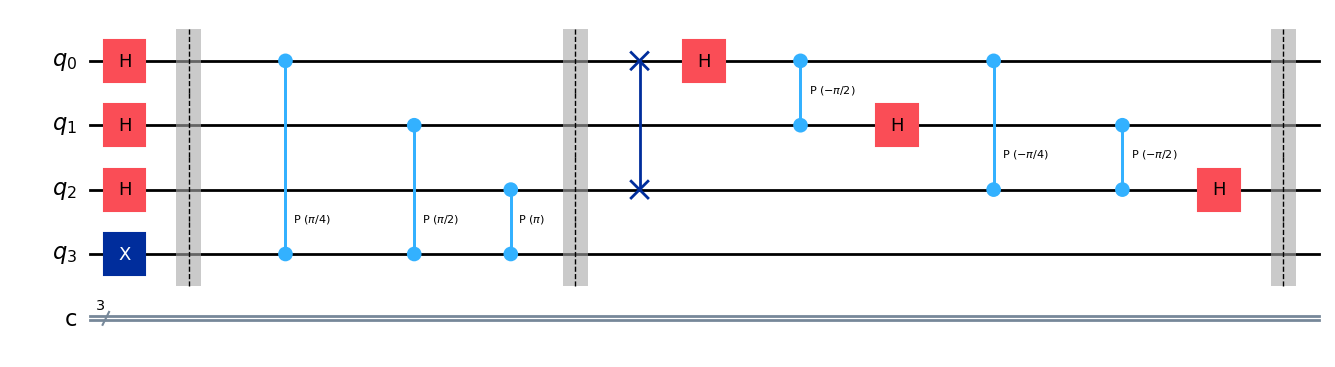

In [6]:
fig = qpe.draw(output="mpl")
fig.savefig(f"{TOPIC_SLUG}_qiskit_circuit.png", bbox_inches="tight", dpi=150)
fig

In [7]:
# --- Cross-check (a): hand-built gate matrices in NumPy, same basis ordering as the framework ---
H = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]])

def cp_matrix(angle):
    # 4x4 controlled-phase matrix, basis order |00>,|01>,|10>,|11> (control=first qubit here)
    m = np.eye(4, dtype=complex)
    m[3, 3] = np.exp(1j * angle)
    return m

print("H gate:\n", np.round(H, 4))
for k in range(N_COUNTING):
    angle = LAMBDA * (2 ** k)
    print(f"\nControlled-P({angle:.4f}) matrix (control=counting[{k}], target):\n", np.round(cp_matrix(angle), 4))

# --- Cross-check (b): framework's own operator extraction, applied to the same initial state ---
qpe_no_measure = qpe.remove_final_measurements(inplace=False)
op = Operator(qpe_no_measure)
sv_from_op = Statevector.from_int(0, dims=2 ** N_QUBITS).evolve(op)
sv_from_instruction = Statevector.from_instruction(qpe_no_measure)

max_delta = np.max(np.abs(sv_from_op.data - sv_from_instruction.data))
print(f"\nMax amplitude delta between Operator-evolution and direct Statevector simulation: {max_delta:.2e}")
assert max_delta < 1e-9, "Operator and Statevector simulation disagree -- fix before proceeding"
print("Matrix cross-check PASSED.")

H gate:
 [[ 0.7071  0.7071]
 [ 0.7071 -0.7071]]

Controlled-P(0.7854) matrix (control=counting[0], target):
 [[1.    +0.j     0.    +0.j     0.    +0.j     0.    +0.j    ]
 [0.    +0.j     1.    +0.j     0.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.    +0.j     1.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.    +0.j     0.    +0.j     0.7071+0.7071j]]

Controlled-P(1.5708) matrix (control=counting[1], target):
 [[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+1.j]]

Controlled-P(3.1416) matrix (control=counting[2], target):
 [[ 1.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  1.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  1.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j -1.+0.j]]

Max amplitude delta between Operator-evolution and direct Statevector simulation: 4.74e-17
Matrix cross-check PASSED.


In [8]:
def normalize_global_phase(statevector_data):
    data = np.array(statevector_data, dtype=complex)
    idx = int(np.argmax(np.abs(data) > 1e-9))  # first nonzero amplitude in ascending bitstring order
    phase = np.angle(data[idx])
    return data * np.exp(-1j * phase)

sv = Statevector.from_instruction(qpe_no_measure)
amps = normalize_global_phase(sv.data)

probs = {}
for i, amp in enumerate(amps):
    bitstring = format(i, f"0{N_QUBITS}b")  # qubit 0 = rightmost, Qiskit's native int->bitstring convention
    p = abs(amp) ** 2
    if p > 1e-9:
        probs[bitstring] = p
probs = dict(sorted(probs.items()))

print("Normalized amplitudes (nonzero only):")
for i, amp in enumerate(amps):
    if abs(amp) > 1e-9:
        print(f"  |{format(i, f'0{N_QUBITS}b')}>: {amp:.4f}")

print("\nStatevector probability dictionary (sorted by bitstring):")
for k, v in probs.items():
    print(f"  {k}: {v:.6f}")

Normalized amplitudes (nonzero only):
  |1001>: 1.0000-0.0000j

Statevector probability dictionary (sorted by bitstring):
  1001: 1.000000


## Ordering-fix note
No bitstring reversal is needed in this notebook: Qiskit already indexes both statevector
amplitudes and measurement counts with **qubit 0 as the least-significant (rightmost) bit**,
matching the QUBIT ORDERING CONTRACT above. The CUDA-Q notebook applies an explicit reversal
in its own cell to match this same convention.


In [9]:
qpe_measured = qpe.copy()
qpe_measured.measure(list(range(N_COUNTING)), list(range(N_COUNTING)))

sim = AerSimulator(seed_simulator=SEED)
job = sim.run(qpe_measured, shots=SHOTS, seed_simulator=SEED)
counts = job.result().get_counts()

meas_probs = {k: v / SHOTS for k, v in sorted(counts.items())}
print("Measured counts:", dict(sorted(counts.items())))
print("Measured probabilities:", meas_probs)

# Hand-computed expectation: THETA = 1/8 = 0.001 in binary is EXACT in 3 bits,
# so every shot should measure the counting register as the same bitstring.
expected_bitstring = format(int(round(THETA * (2 ** N_COUNTING))), f"0{N_COUNTING}b")
print(f"\nExpected dominant outcome (hand-computed): '{expected_bitstring}' with probability ~1.0")
assert meas_probs.get(expected_bitstring, 0) > 0.99, "Measured distribution does not match hand-computed expectation"
print("Measurement self-check PASSED.")

Measured counts: {'001': 10000}
Measured probabilities: {'001': 1.0}

Expected dominant outcome (hand-computed): '001' with probability ~1.0
Measurement self-check PASSED.


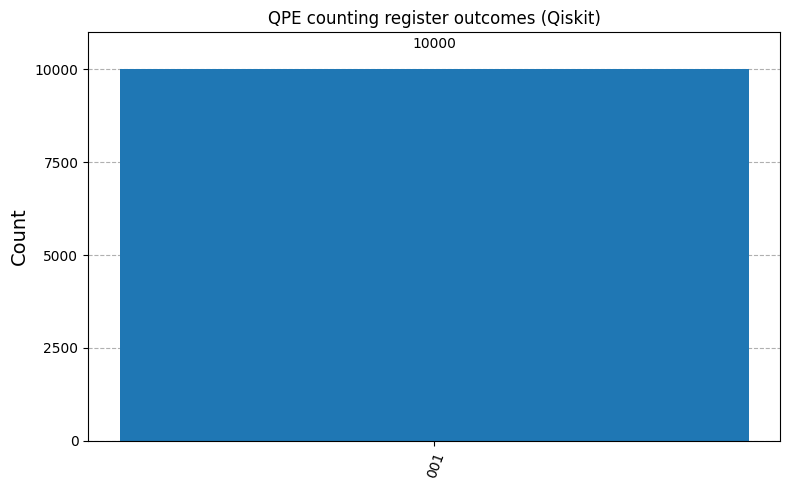

In [10]:
fig2 = plot_histogram(counts, figsize=(8, 5), title="QPE counting register outcomes (Qiskit)")
fig2.savefig(f"{TOPIC_SLUG}_qiskit_histogram.png", bbox_inches="tight", dpi=150)
fig2

In [11]:
print("Circuit depth:", qpe_measured.depth())
print("Gate counts:", qpe_measured.count_ops())

Circuit depth: 11
Gate counts: OrderedDict({'h': 6, 'cp': 6, 'barrier': 3, 'measure': 3, 'x': 1, 'swap': 1})


## Convention notes (restated)
- Qubit ordering: qubit 0 = rightmost bit, **no reversal applied** (Qiskit native).
- Global phase: normalized so the first nonzero amplitude in ascending bitstring order is real and positive.
- THETA = 1/8 chosen to be exactly representable in N_COUNTING = 3 bits, so the measured distribution
  is a single deterministic spike (no shot noise) -- this makes cross-checking against CUDA-Q unambiguous.


In [12]:
QISKIT_RESULT = meas_probs
print("QISKIT_RESULT =", QISKIT_RESULT)

QISKIT_RESULT = {'001': 1.0}


In [13]:
# --- Diff-check against CUDA-Q (paste CUDAQ_RESULT here after running the CUDA-Q notebook) ---
# CUDAQ_RESULT = {...}
# common_keys = set(QISKIT_RESULT) | set(CUDAQ_RESULT)
# max_delta = max(abs(QISKIT_RESULT.get(k, 0) - CUDAQ_RESULT.get(k, 0)) for k in common_keys)
# print(f"Max probability delta: {max_delta:.2e}")
# assert max_delta < 1e-3, "Qiskit and CUDA-Q results disagree beyond tolerance"

# Hand-computed sanity check (independent of simulation):
expected_theta_bits = format(int(round(THETA * (2 ** N_COUNTING))), f"0{N_COUNTING}b")
print(f"Hand-computed expected outcome: '{expected_theta_bits}' with probability ~1.0")
assert QISKIT_RESULT.get(expected_theta_bits, 0) > 0.99
print("Final sanity check PASSED.")

Hand-computed expected outcome: '001' with probability ~1.0
Final sanity check PASSED.
